# Incremental DBSCAN: notebook demo của nhóm 1

*Dữ liệu dùng trong demo là dữ liệu mô phỏng (xem `data/README_data.md`). DBSCAN và Incremental DBSCAN được nhóm tự cài trong `src/`; NumPy/Pandas dùng cho dữ liệu, sklearn chỉ dùng làm baseline và so sánh.*

**Trọng tâm:** giải thích DBSCAN và Incremental DBSCAN bằng ví dụ insert gộp cụm, delete tách cụm; minh họa 2D và kiểm tra dữ liệu nhiều chiều. Phần so sánh thuật toán cùng nhóm ở mục 8.2 dùng DBSCAN, HDBSCAN và OPTICS.

| Yêu cầu | Mục trong notebook |
|---|---|
| Khái niệm và ví dụ theo từng bước | 5.1 (insert/Merge) và 5.2 (delete/Split) |
| Tự cài đặt, OOP, minh họa 2D và n chiều | 4–6; cài đặt trong `src/clustering/` |
| Đối chiếu với thư viện và thuật toán cùng nhóm | 7.1, 8.1 và 8.2 |

Các phần kiểm tra nhiều bộ dữ liệu trong mục 7.2 là phần bổ sung; khi trình bày chính, tập trung vào ví dụ 2D, cập nhật insert/delete và bảng so sánh ở mục 8.2.


---
#### **0. MÔI TRƯỜNG**

In [1]:
## Thư viện và thư mục gốc repo (mở notebook từ gốc repo hay từ notebooks/ đều được)
import os
import sys
import platform
import time
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def repo_root(start=None):
    here = Path(start or Path.cwd()).resolve()
    for d in (here, *here.parents):
        if (d / 'src' / 'clustering').is_dir():
            return d
    raise FileNotFoundError('không thấy src/clustering: hãy mở notebook bên trong repo')


ROOT = repo_root()
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
pd.set_option('display.max_columns', None); pd.set_option('display.width', 200)
print(ROOT.name, '| Python', platform.python_version(), '| numpy', np.__version__, '| pandas', pd.__version__)

INCREMENTAL_DBSCAN_NHOM_1 | Python 3.13.2 | numpy 2.5.3 | pandas 2.2.3


In [2]:
## Code của nhóm: thuật toán (src/clustering), tiền xử lý (src/preprocessing), trực quan (src/visualization)
from src.clustering.dbscan import DBSCAN
from src.clustering.incremental_dbscan import IncrementalDBSCAN
from src.core.data_point import PointType
from src.experiments.engine import IncrementalEngine
from src.experiments.update_cases import describe_update, update_seeds
from src.preprocessing.cleaning import clean_card_table, quality_report
from src.preprocessing.scaler import ManualScaler
from src.preprocessing.stream_scaling import stream_coordinates
from src.visualization import (ClusterVisualizer, load_scenario, plot_algorithm_contrast, plot_k_distance, run_scenario, stream_snapshots,
                               type_counts)
vis = ClusterVisualizer()

In [3]:
## Đối chứng bằng thư viện (chỉ dùng để so sánh, không nằm trong src/)
import sklearn
from sklearn.metrics import adjusted_rand_score, silhouette_score
from baseline.sklearn_dbscan import RefitDBSCAN, ambiguous_by_step, read_stream, replay_stream
from baseline.update_experiments import (delete_gallery, insert_gallery, plot_delete_steps, plot_insert_steps, plot_update_pair,
                                        snapshots_equivalent, stream_example)
print('scikit-learn', sklearn.__version__)

scikit-learn 1.6.1


---
#### **1. NẠP DỮ LIỆU**

##### *1.1. Kịch bản toy: ví dụ trong tài liệu lý thuyết của nhóm*

In [4]:
## Kịch bản R02 Case 4 (Merge): 12 điểm 2 chiều, Eps = 1.1, MinPts = 4, rồi chèn p
sc_merge = load_scenario('toy', 'r02_4_merge')
pd.DataFrame(sc_merge['coords'], index=sc_merge['names'], columns=['x', 'y']).T

,A1,A2,A3,A4,A5,A6,B1,B2,B3,B4,B5,B6
x,-1.0,0.0,1.0,-1.0,0.0,1.0,2.8,3.8,4.8,2.8,3.8,4.8
y,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0


In [5]:
## Dòng cập nhật của kịch bản: chèn p tại (1.9, 0.5)
sc_merge['updates']

[{'op': 'insert', 'point_id': 'p', 'coords': array([1.9, 0.5])}]

##### *1.2. Bản đồ giao dịch ATM 2D và luồng cập nhật theo ngày*

In [6]:
## 1200 giao dịch rút tiền, tọa độ x_km, y_km trên bản đồ thành phố mô phỏng; hotspot_id là nhãn thật (-1 là giao dịch lẻ)
atm = pd.read_csv('data/raw/bank_geo/atm_txn_2d.csv', encoding='utf-8')
print(atm.shape)
atm.head()

(1200, 11)


,txn_id,x_km,y_km,hotspot_id,timestamp,atm_id,customer_id,amount_vnd,atm_network,district_id,atm_distance_km
0,ATM00001,16.031,6.190,4,2025-03-13 20:22:03,A23,C0055,2050000,own,D06,0.181
1,ATM00002,13.903,7.521,4,2025-04-06 09:36:34,A29,C0299,250000,own,D06,0.343
2,ATM00003,19.348,6.461,2,2025-03-08 06:13:08,A11,C0467,2650000,own,D03,0.594
3,ATM00004,15.189,20.727,5,2025-03-13 15:26:53,A33,C0068,2250000,partner,D05,0.840
4,ATM00005,27.023,18.671,1,2025-03-17 23:53:44,A09,C0198,400000,own,D02,0.777


In [7]:
## Luồng ATM: D0 có 529 điểm, 119 update (mỗi update là một ngày); verified_case là case suy ra bằng fit lại trước và sau update
d0_atm, upd_atm, par_atm, feat_atm = read_stream('data/raw/bank_geo/atm_stream')
eps_atm = par_atm['eps_km']
print('D0:', d0_atm.shape, '| update:', upd_atm.shape, '| Eps =', eps_atm, 'km | MinPts =', par_atm['minpts'])
upd_atm.groupby(['op', 'verified_case']).size().rename('số update')

D0: (529, 5) | update: (119, 10) | Eps = 0.5 km | MinPts = 4


op      verified_case          
delete  PotentialSplit_NonSplit     7
        PotentialSplit_Split       12
        Reduction                  25
        Removal                     6
insert  Absorption                 32
        Creation                   13
        Merge                      12
        Noise                      12
Name: số update, dtype: int64

##### *1.3. Giao dịch thẻ 5 chiều (cố tình có lỗi dữ liệu)*

In [8]:
## Bảng thẻ thô: 5 đặc trưng số, có ô thiếu, dòng trùng, kênh viết không thống nhất, giờ sai
card_raw = pd.read_csv('data/raw/bank_card/card_txn_5d.csv', encoding='utf-8')
customers = pd.read_csv('data/raw/bank_card/customers.csv', encoding='utf-8')
districts = pd.read_csv('data/raw/bank_geo/districts.csv', encoding='utf-8')
dac_trung = ['amount_vnd', 'hour_of_day', 'distance_from_home_km', 'txns_last_7d', 'merchant_risk_score']
print(card_raw.shape)
card_raw[['txn_id', 'timestamp', 'channel'] + dac_trung].head()

(1500, 13)


,txn_id,timestamp,channel,amount_vnd,hour_of_day,distance_from_home_km,txns_last_7d,merchant_risk_score
0,TXN001280,2025-03-06 13:13:48,CONTACTLESS,173000.0,13.23,6.29,8.0,0.201
1,TXN001099,2025-03-20 22:57:00,ONLINE,655000.0,22.95,0.12,4.0,0.319
2,TXN000267,2025-03-30 12:40:12,CONTACTLESS,213000.0,12.67,2.60,7.0,0.075
3,TXN000506,2025-03-15 01:10:48,ATM,33000.0,1.18,6.76,15.0,0.650
4,TXN001297,2025-03-30 02:43:12,ATM,41000.0,2.72,7.03,15.0,0.697


---
#### **2. TIỀN XỬ LÝ**

*Chi tiết từng bước ở notebook D02; ở đây chạy hàm gộp `clean_card_table` của nhóm và chuẩn hóa bằng `ManualScaler` tự viết.*

In [9]:
## Kiểm tra chất lượng trước khi làm sạch: số dòng lỗi theo từng loại
quality_report(card_raw, customers, districts)

,check,column,n_rows,share
0,missing_value,amount_vnd,23,0.0153
1,missing_value,hour_of_day,22,0.0147
2,missing_value,distance_from_home_km,18,0.0120
3,missing_value,txns_last_7d,31,0.0207
4,missing_value,merchant_risk_score,18,0.0120
5,duplicate_row_exact_copy,(whole row),8,0.0053
6,duplicate_txn_id,txn_id,8,0.0053
7,inconsistent_spelling_or_case,channel,104,0.0693
8,mixed_timestamp_format_dd_mm_yyyy,timestamp,30,0.0200
9,impossible_timestamp,timestamp,6,0.0040


In [10]:
## Làm sạch: bỏ dòng trùng, chuẩn hóa kênh, sửa giờ, điền thiếu bằng trung vị theo nhóm (chỉ học từ D0 = 500 giao dịch sớm nhất)
card_sach, trung_vi_d0 = clean_card_table(card_raw, customers, districts)
print('trước:', len(card_raw), 'dòng | sau:', len(card_sach), 'dòng | còn ô thiếu:', int(card_sach[dac_trung].isna().sum().sum()))

trước: 1500 dòng | sau: 1492 dòng | còn ô thiếu: 0


In [11]:
## Số tiền lệch phải rất mạnh nên lấy log10, rồi chuẩn hóa z-score bằng ManualScaler fit trên D0 (không dùng thông tin tương lai)
cot_z = ['log10_amount_vnd'] + dac_trung[1:]
scaler = ManualScaler('standard').fit(card_sach.loc[card_sach['is_d0'], cot_z])
Z_card = scaler.transform(card_sach[cot_z])
pd.DataFrame({'mean D0': scaler.center_, 'std D0': scaler.scale_, 'std sau chuẩn hóa': Z_card.std(axis=0)}, index=cot_z).round(3)

,mean D0,std D0,std sau chuẩn hóa
log10_amount_vnd,5.588,0.789,0.996
hour_of_day,12.913,6.749,0.990
distance_from_home_km,17.720,56.553,0.966
txns_last_7d,7.772,5.580,0.960
merchant_risk_score,0.341,0.212,0.965


In [12]:
## Luồng thẻ phát lại bằng hằng số cố định trong params.json (mọi thuật toán thấy cùng tọa độ); điểm mới chỉ transform, không fit lại
d0_card, upd_card, par_card, feat_card = read_stream('data/raw/bank_card/card_stream')
X0_card = stream_coordinates(par_card, d0_card, feat_card)
print('D0 thẻ:', X0_card.shape, '| Eps =', par_card['eps'], '| MinPts =', par_card['minpts'], '| update:', len(upd_card))

D0 thẻ: (500, 5) | Eps = 0.4 | MinPts = 6 | update: 300


In [13]:
## Bản đồ ATM: hai trục cùng đơn vị km nên không chuẩn hóa (chuẩn hóa sẽ làm méo khoảng cách thật)
atm[['x_km', 'y_km']].describe().round(2)

,x_km,y_km
count,1200.00,1200.00
mean,17.32,11.79
std,7.69,5.45
min,0.62,0.70
25%,8.78,6.91
50%,19.63,10.92
75%,23.84,16.76
max,31.34,23.40


---
#### **3. CHỌN THAM SỐ EPS VÀ MINPTS**

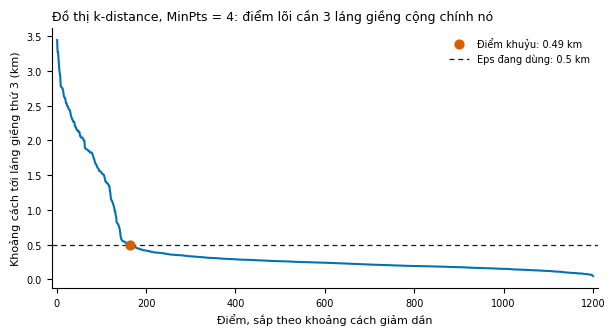

In [14]:
## Đồ thị k-distance (k = MinPts = 4, khoảng cách tính bằng numpy): khuỷu nằm gần 0.5 km, đúng Eps đang dùng
fig = plot_k_distance(atm[['x_km', 'y_km']].to_numpy(), min_pts=4, eps=0.5)

In [15]:
## Thử vài Eps quanh khuỷu bằng DBSCAN của nhóm: từ 0.5 đến 0.8 đều ra 6 cụm và ARI gần bằng nhau, nên kết quả không nhạy với Eps quanh khuỷu
xy_atm, nhan_that = atm[['x_km', 'y_km']].to_numpy(), atm['hotspot_id'].to_numpy()
dong = []
for eps in (0.3, 0.4, 0.5, 0.6, 0.8):
    nhan = np.array(DBSCAN(eps, 4).fit(xy_atm).get_labels())
    dong.append({'eps': eps, 'số cụm': len(set(nhan) - {-1}), 'số nhiễu': int((nhan == -1).sum()), 'ARI': round(adjusted_rand_score(nhan_that, nhan), 4)})
pd.DataFrame(dong)

,eps,số cụm,số nhiễu,ARI
0,0.3,39,237,0.4895
1,0.4,13,162,0.8100
2,0.5,6,142,0.9925
3,0.6,6,141,0.9945
4,0.8,6,132,0.9895


---
#### **4. FIT BAN ĐẦU**

In [16]:
## IncrementalDBSCAN kế thừa fit từ DBSCAN: fit D0 của luồng ATM, Eps = 0.5 km, MinPts = 4
X0_atm = stream_coordinates(par_atm, d0_atm, feat_atm)
mo_hinh = IncrementalEngine(eps_atm, par_atm['minpts']).fit(X0_atm)
print(type(mo_hinh).__mro__[1].__name__, '| điểm:', mo_hinh.n_points, '| cụm:', mo_hinh.n_clusters, '| nhiễu:', mo_hinh.n_noise)

IncrementalDBSCAN | điểm: 529 | cụm: 44 | nhiễu: 24


In [17]:
## Mỗi điểm là một đối tượng DataPoint: id, tọa độ, loại điểm, cụm và bộ nhớ đệm id láng giềng
mo_hinh.points[0]

DataPoint(id=0, coords=[3.862, 6.429], cluster=0, type=CORE, neighbor_ids=[0, 47, 112, 219, 356])

In [18]:
## Số điểm lõi, biên, nhiễu (Counter trên list để khóa là chuỗi)
Counter([p.point_type.value for p in mo_hinh.points.values()])

Counter({'CORE': 335, 'BORDER': 170, 'NOISE': 24})

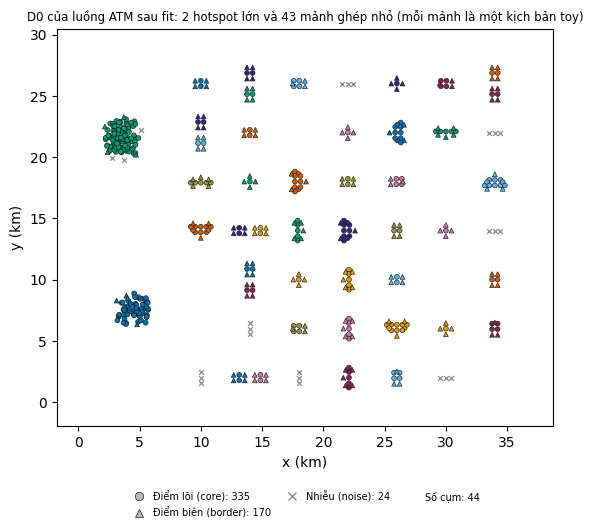

In [19]:
## Kết quả fit ban đầu trên bản đồ: màu là cụm, hình tròn là lõi, tam giác là biên, dấu x là nhiễu (các ô cách nhau 4 km là các mảnh ghép từ kịch bản toy)
fig, ax = plt.subplots(figsize=(6.4, 5.6))
ax = ClusterVisualizer(point_size=12).plot_2d(mo_hinh, ax=ax, fill=None, axis_labels=('x (km)', 'y (km)'),
                                              title='D0 của luồng ATM sau fit: 2 hotspot lớn và 43 mảnh ghép nhỏ (mỗi mảnh là một kịch bản toy)')
ax.title.set_fontsize(8.5)

---
#### **5. CẬP NHẬT: INSERT VÀ DELETE**

##### *5.1. Chèn từng bước: R02 Case 4 (Merge)*

In [20]:
## Fit 12 điểm rồi xem trạng thái từng điểm trước khi chèn
toy = IncrementalEngine(sc_merge['eps'], sc_merge['min_pts']).fit(sc_merge['coords'])
truoc = toy.snapshot()
pd.DataFrame({'điểm': sc_merge['names'], 'số láng giềng': [toy.points[i].neighbor_count for i in range(12)],
              'loại': [toy.points[i].point_type.value for i in range(12)], 'cụm': truoc['labels']})

,điểm,số láng giềng,loại,cụm
0,A1,3,BORDER,0
1,A2,4,CORE,0
2,A3,3,BORDER,0
3,A4,3,BORDER,0
4,A5,4,CORE,0
5,A6,3,BORDER,0
6,B1,3,BORDER,1
7,B2,4,CORE,1
8,B3,3,BORDER,1
9,B4,3,BORDER,1


In [21]:
## Chèn p: insert trả id mới (12); thuật toán chỉ xét lân cận Eps của p thay vì chạy lại trên cả 13 điểm
id_p = toy.insert(sc_merge['updates'][0]['coords'])
sau = toy.snapshot()
ten = sc_merge['names'] + ['p']
print('id của p:', id_p, '| láng giềng của p:', sorted(ten[i] for i in toy.points[id_p].neighbor_ids))

id của p: 12 | láng giềng của p: ['A3', 'A6', 'B1', 'B4', 'p']


In [22]:
## Lõi mới và UpdSeed (Ester và cộng sự, 1998): lõi sau update nằm trong Eps của một điểm vừa thành lõi
seed, loi_moi = update_seeds(truoc, sau, 'insert', sc_merge['eps'])
print('vừa thành lõi:', sorted(ten[i] for i in loi_moi))
print('UpdSeed     :', sorted(ten[i] for i in seed), '| đáp án:', sc_merge['expected']['updseed'])

vừa thành lõi: ['A3', 'A6', 'B1', 'B4', 'p']
UpdSeed     : ['A2', 'A3', 'A5', 'A6', 'B1', 'B2', 'B4', 'B5', 'p'] | đáp án: ['A2', 'A3', 'A5', 'A6', 'B1', 'B2', 'B4', 'B5', 'p']


In [23]:
## UpdSeed chứa lõi của hai cụm cũ nên đây là Merge: hai cụm nhập làm một
pd.DataFrame({'điểm': ten, 'cụm trước': list(truoc['labels']) + ['(chưa có)'], 'cụm sau': sau['labels'],
              'loại sau': [toy.points[i].point_type.value for i in range(13)]}).T

,0,1,2,3,4,5,6,7,8,9,10,11,12
điểm,A1,A2,A3,A4,A5,A6,B1,B2,B3,B4,B5,B6,p
cụm trước,0,0,0,0,0,0,1,1,1,1,1,1,(chưa có)
cụm sau,0,0,0,0,0,0,0,0,0,0,0,0,0
loại sau,BORDER,CORE,CORE,BORDER,CORE,CORE,CORE,CORE,BORDER,CORE,CORE,BORDER,CORE


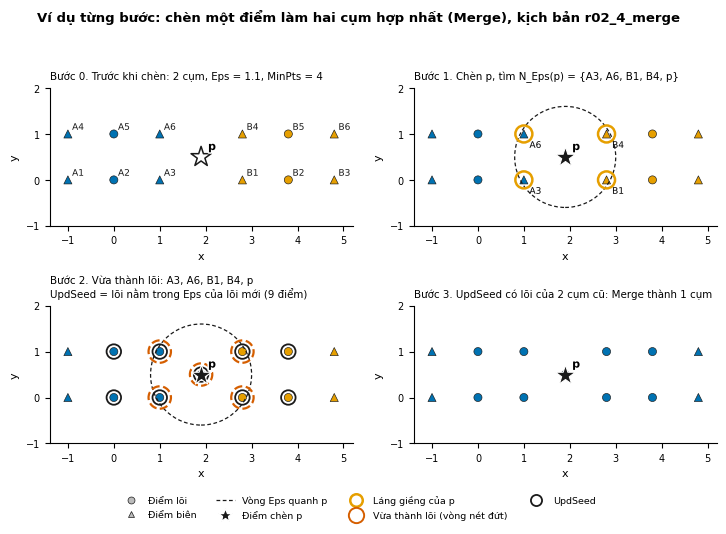

In [24]:
## Hình từng bước của phép chèn: lân cận Eps của p, điểm vừa thành lõi, UpdSeed, kết luận Merge
fig = plot_insert_steps('r02_4_merge')

##### *5.2. Xóa từng bước: R03 Case 3A (Split)*

In [25]:
## Kịch bản Split: xóa p, điểm cầu nối duy nhất giữa hai nửa của một cụm
sc_split = load_scenario('toy', 'r03_3a_split')
toy2 = IncrementalEngine(sc_split['eps'], sc_split['min_pts']).fit(sc_split['coords'])
ten2 = sc_split['names']
truoc2 = toy2.snapshot()
toy2.delete(ten2.index('p'))
sau2 = toy2.snapshot()
seed2, mat_loi = update_seeds(truoc2, sau2, 'delete', sc_split['eps'])
print('mất tính lõi:', sorted(ten2[i] for i in mat_loi), '| UpdSeed:', sorted(ten2[i] for i in seed2), '| đáp án:', sc_split['expected']['updseed'])

mất tính lõi: ['p'] | UpdSeed: ['A', 'E'] | đáp án: ['A', 'E']


In [26]:
## A và E không còn nối với nhau qua chuỗi lõi nên cụm tách đôi; I mất điểm lõi kề nên thành nhiễu (-1)
cum_sau = dict(zip([ten2[i] for i in sau2['ids']], sau2['labels'].tolist()))
pd.DataFrame({'cụm trước': truoc2['labels'].tolist(), 'cụm sau': [cum_sau.get(t, '(đã xóa)') for t in ten2]}, index=ten2).T

,A,B,C,D,E,F,G,H,I,p
cụm trước,0,0,0,0,0,0,0,0,0,0
cụm sau,0,0,0,0,1,1,1,1,-1,(đã xóa)


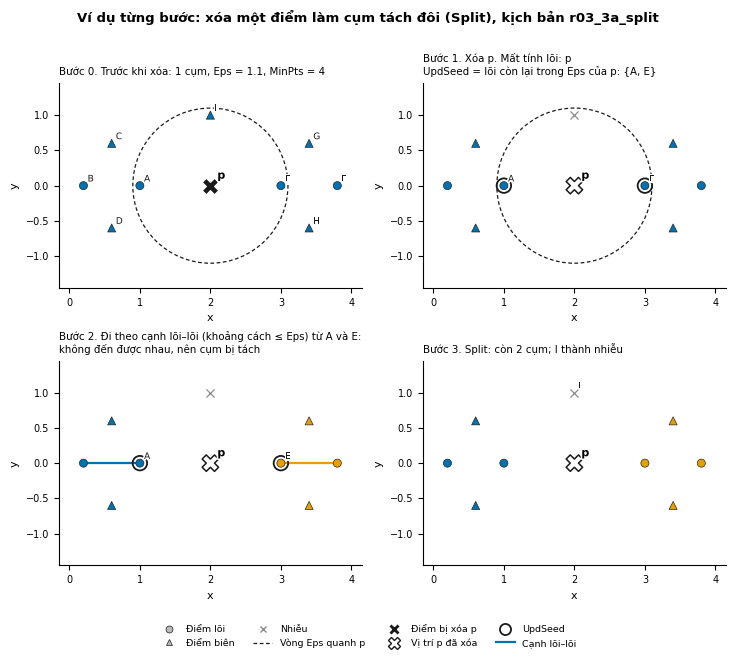

In [27]:
## Hình từng bước của phép xóa: điểm mất tính lõi, UpdSeed, đi theo cạnh lõi–lõi để kiểm tra liên thông, kết luận Split
fig = plot_delete_steps('r03_3a_split')

##### *5.3. Luồng ATM: 119 update liên tiếp*

In [28]:
## Phát lại cả luồng ATM bằng IncrementalDBSCAN, giữ snapshot sau mỗi step
khung = stream_snapshots(IncrementalEngine, 'data/raw/bank_geo/atm_stream')
print(len(khung) - 1, 'update | số cụm đầu:', type_counts(khung[0]['snapshot'])['clusters'], '| số cụm cuối:', type_counts(khung[-1]['snapshot'])['clusters'])

119 update | số cụm đầu: 44 | số cụm cuối: 51


In [29]:
## Mỗi update một dòng: số điểm đổi trạng thái, cỡ UpdSeed; phép xóa thêm số điểm được gán lại nhãn (cách cài của nhóm đi lại cả cụm bị ảnh hưởng)
mo_ta = pd.DataFrame([{'step': f['step'], 'op': f['op'], 'case': f['case'],
                       **describe_update(khung[k - 1]['snapshot'], f['snapshot'], f['op'], f['point_id'], f['eps'])} for k, f in enumerate(khung) if k])
mo_ta.groupby(['op', 'case'])[['n_updseed', 'n_changed', 'n_reprocessed', 'n_before']].median()

n_updseed  n_changed  n_reprocessed  n_before
op     case                                                                  
delete PotentialSplit_NonSplit        3.0        0.0           13.0     541.0
       PotentialSplit_Split           3.0        6.5           11.5     544.0
       Reduction                      2.0        1.0            7.0     542.0
       Removal                        0.0        4.0            5.0     534.5
insert Absorption                     4.0        0.0            NaN     541.0
       Creation                       1.0        3.0            NaN     537.0
       Merge                          6.0        6.5            NaN     539.5
       Noise                          0.0        0.0            NaN     540.0

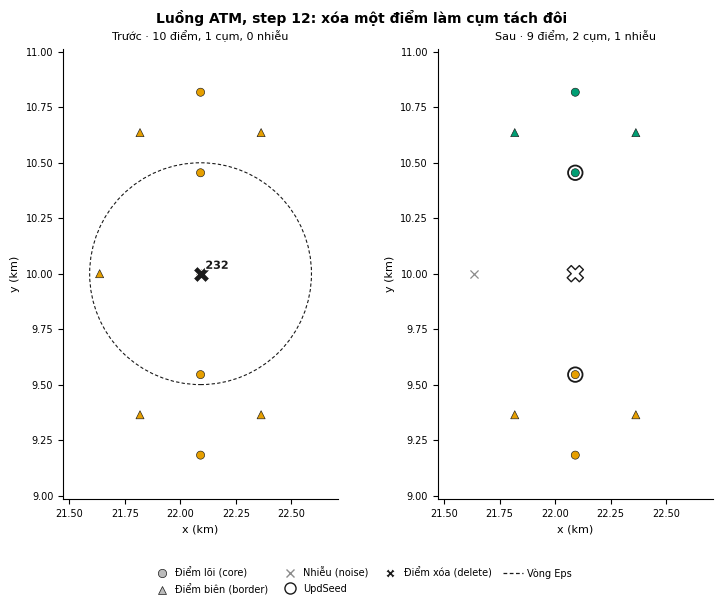

In [30]:
## Một lần Split thật trong luồng: cắt bán kính 1.6 km quanh điểm bị xóa; UpdSeed tính từ hai snapshot đầy đủ
vd = stream_example('data/raw/bank_geo/atm_stream', 'PotentialSplit_Split')
fig = plot_update_pair(vd, f"Luồng ATM, step {vd['step']}: xóa một điểm làm cụm tách đôi")

---
#### **6. TRỰC QUAN: CÁC TRƯỜNG HỢP CHÈN VÀ XÓA**

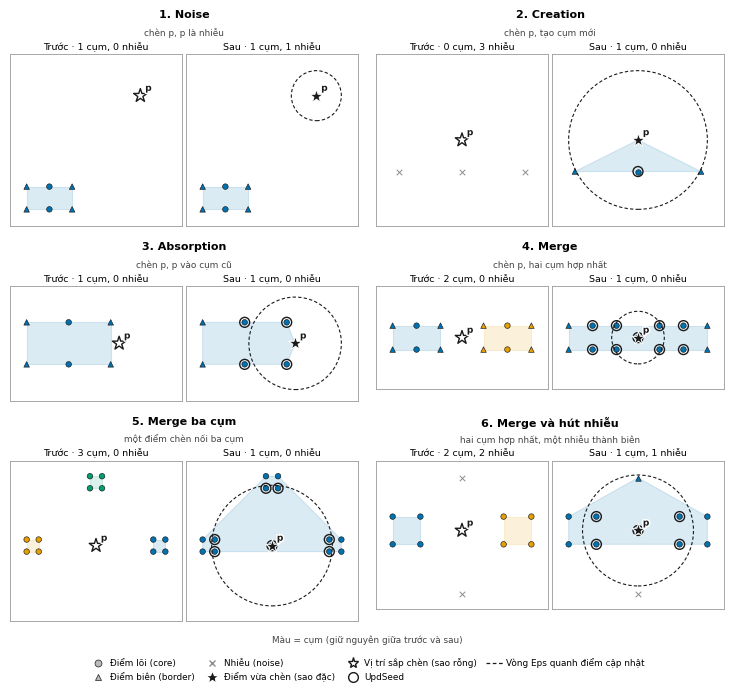

In [31]:
## Sáu ca chèn chạy trên IncrementalDBSCAN: Noise, Creation, Absorption, Merge, một điểm nối 3 cụm, hợp nhất và hút nhiễu
fig = vis.plot_case_gallery(insert_gallery(), n_pair_cols=2)

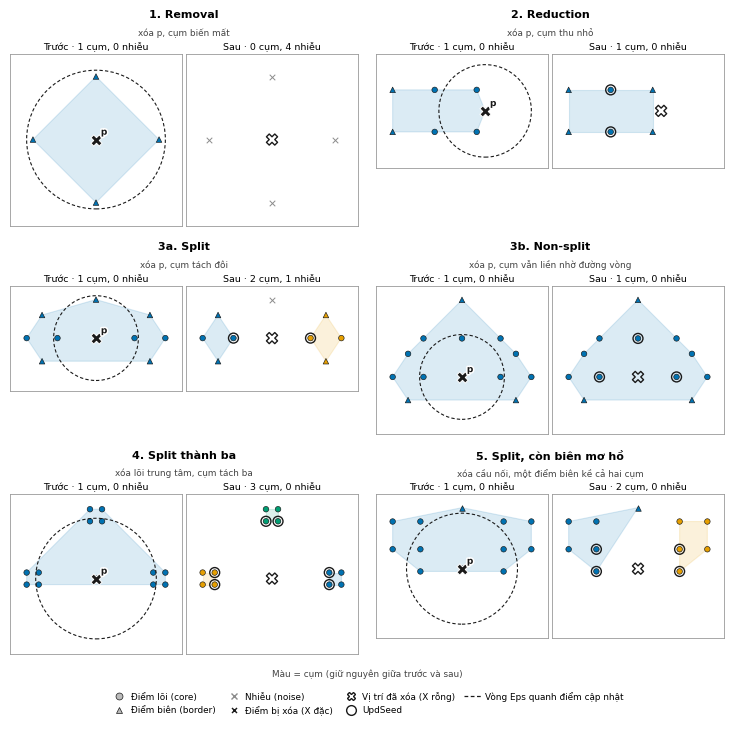

In [32]:
## Sáu ca xóa: Removal, Reduction, Split, Non-split, tách 3, xóa cầu còn điểm biên mơ hồ
fig = vis.plot_case_gallery(delete_gallery(), n_pair_cols=2)

---
#### **7. ĐÁNH GIÁ**

##### *7.1. Đúng so với thư viện: sau mỗi update, bản gia tăng phải bằng sklearn fit lại trên cùng tập điểm*

In [33]:
## Ba luồng (719 update): cùng loại điểm, cùng cách chia lõi; điểm biên mơ hồ được phép khác cụm
luong = {'atm_stream': 'bank_geo', 'card_stream': 'bank_card', 'card_stream_hard': 'bank_card'}
bang_dung = []
for ten_luong, thu_muc in luong.items():
    duong_dan = f'data/raw/{thu_muc}/{ten_luong}'
    d0, upd, par, feat = read_stream(duong_dan)
    mo_ho = ambiguous_by_step(par, upd)
    a, b = stream_snapshots(IncrementalEngine, duong_dan), stream_snapshots(RefitDBSCAN, duong_dan)
    khop = [snapshots_equivalent(x['snapshot'], y['snapshot'], par.get('eps', par.get('eps_km')), mo_ho.get(x['step'], [])) for x, y in zip(a, b)]
    bang_dung.append({'luồng': ten_luong, 'số chiều': len(feat), 'fit D0 tương đương': khop[0], 'số update': len(khop) - 1,
                      'update tương đương': sum(khop[1:])})
pd.DataFrame(bang_dung)

,luồng,số chiều,fit D0 tương đương,số update,update tương đương
0,atm_stream,2,True,119,119
1,card_stream,5,True,300,300
2,card_stream_hard,5,True,300,300


##### *7.2. Tám bộ dữ liệu: fit 60%, chèn 40% còn lại, xóa 20% rồi chèn lại (mục 2.2)*

In [34]:
## Kết quả của baseline/dataset_comparison.py: mỗi update so với sklearn fit lại trên cùng tập điểm; nếu chưa có file thì chạy lại (khoảng 3 phút)
duong_d22 = Path('data/processed/experiments/d22/dataset_comparison.csv')
if duong_d22.exists():
    bang_d22 = pd.read_csv(duong_d22, encoding='utf-8')
else:
    from baseline.dataset_comparison import DATASETS, run_dataset
    bang_d22 = pd.DataFrame([run_dataset(*spec)[0] for spec in DATASETS])
bang_d22[['dataset', 'dims', 'n', 'eps', 'minpts', 'n_updates', 'equivalent_steps', 'ari_incremental_truth', 'ari_sklearn_truth', 'clusters']].round(3)

,dataset,dims,n,eps,minpts,n_updates,equivalent_steps,ari_incremental_truth,ari_sklearn_truth,clusters
0,moons,2,500,0.21,8,400,400,0.972,0.972,2
1,rings,2,500,0.30,8,400,400,1.000,1.000,2
2,blobs có nhiễu,2,500,0.24,8,400,400,0.930,0.930,3
3,ATM 2D,2,1200,0.50,4,960,960,0.993,0.993,6
4,ATM 2D khó,2,2000,0.40,4,1600,1600,0.509,0.509,21
5,blobs 5D,5,860,0.80,10,688,688,0.994,0.994,4
6,thẻ 5D,5,1492,0.65,10,1193,1193,0.997,0.997,4
7,thẻ 5D khó,5,1592,0.30,15,1273,1273,0.427,0.427,3


In [35]:
## Tổng số update và số update khớp sklearn trên cả tám bộ
print('tổng update:', int(bang_d22['n_updates'].sum()), '| khớp sklearn:', int(bang_d22['equivalent_steps'].sum()))

tổng update: 6914 | khớp sklearn: 6914


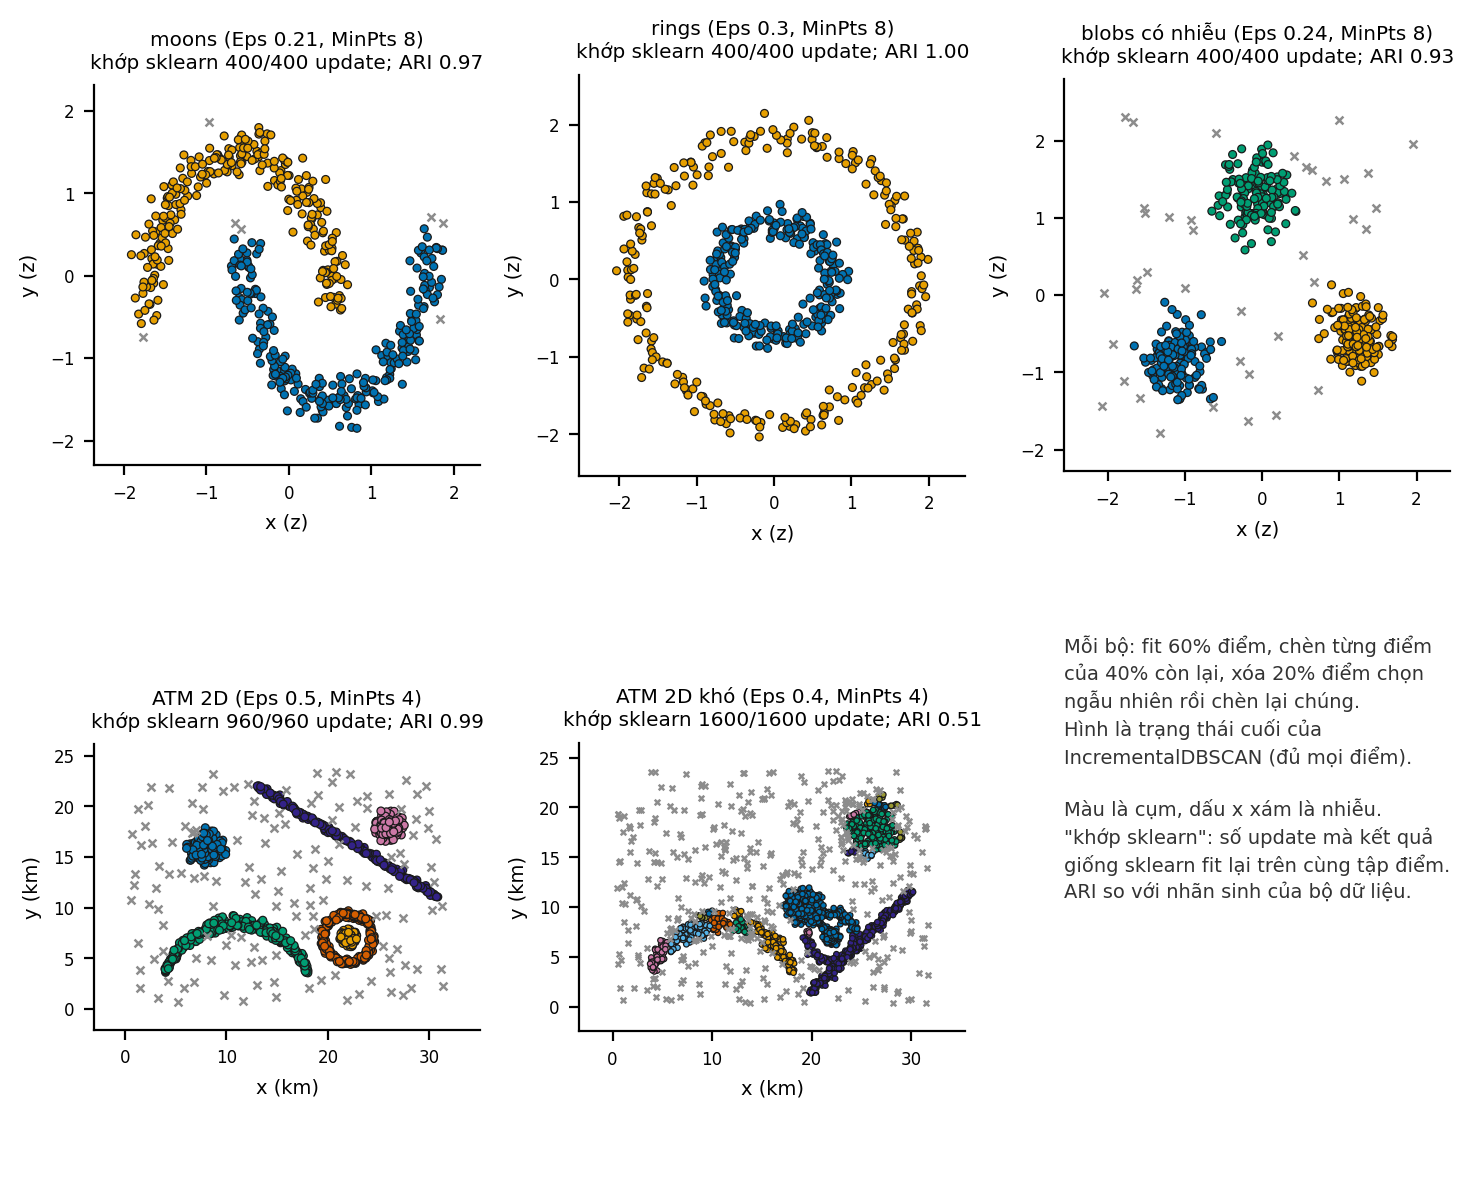

In [36]:
## Kết quả cuối của bản gia tăng trên năm bộ 2 chiều (hình của baseline/dataset_comparison.py)
from IPython.display import Image, display
if Path('report/figures/d22_datasets_2d.png').exists():
    display(Image(filename='report/figures/d22_datasets_2d.png', width=720))

##### *7.3. Chất lượng gom cụm so với nhãn thật*

In [37]:
## Fit cả bản đồ ATM (1200 điểm) rồi chèn thêm từng điểm: kết quả cuối cùng phải như fit một lần
atm_sx = atm.sort_values(['timestamp', 'txn_id']).reset_index(drop=True)
xy_sx = atm_sx[['x_km', 'y_km']].to_numpy()
gia_tang = IncrementalEngine(0.5, 4).fit(xy_sx[:1000])
for p in xy_sx[1000:]:
    gia_tang.insert(p)
nhan_gt = gia_tang.snapshot()['labels']
nhan_fit = np.array(DBSCAN(0.5, 4).fit(xy_sx).get_labels())
print('ARI(gia tăng, fit một lần) =', adjusted_rand_score(nhan_fit, nhan_gt))

ARI(gia tăng, fit một lần) = 1.0


In [38]:
## So với nhãn thật hotspot: ARI và Silhouette (bỏ điểm nhiễu khi tính Silhouette)
co_cum = nhan_gt != -1
pd.Series({'ARI so với nhãn thật': adjusted_rand_score(atm_sx['hotspot_id'], nhan_gt),
           'Silhouette (bỏ nhiễu)': silhouette_score(xy_sx[co_cum], nhan_gt[co_cum]),
           'số cụm': len(set(nhan_gt) - {-1}), 'tỉ lệ nhiễu': float((nhan_gt == -1).mean())}).round(4)

ARI so với nhãn thật     0.9925
Silhouette (bỏ nhiễu)    0.3362
số cụm                   6.0000
tỉ lệ nhiễu              0.1183
dtype: float64

---
#### **8. SO SÁNH MÔ HÌNH**

##### *8.1. Thời gian: gia tăng so với fit lại*

In [39]:
## Luồng ATM, mỗi update đo 5 lần trên bản sao (trung vị): IncrementalDBSCAN của nhóm và sklearn fit lại
t_gt, _ = replay_stream(IncrementalEngine, d0_atm, upd_atm, par_atm, feat_atm, repeats=5)
t_sk, _ = replay_stream(RefitDBSCAN, d0_atm, upd_atm, par_atm, feat_atm, repeats=5)
t0 = time.perf_counter(); DBSCAN(eps_atm, par_atm['minpts']).fit(X0_atm); own_fit_ms = (time.perf_counter() - t0) * 1000
bang_tg = pd.DataFrame({'IncrementalDBSCAN của nhóm (ms)': t_gt[t_gt['step'] > 0].groupby('op')['update_seconds'].median() * 1000,
                        'sklearn fit lại (ms)': t_sk[t_sk['step'] > 0].groupby('op')['update_seconds'].median() * 1000})
bang_tg['DBSCAN của nhóm fit lại (ms)'] = own_fit_ms
bang_tg.round(3)

,IncrementalDBSCAN của nhóm (ms),sklearn fit lại (ms),DBSCAN của nhóm fit lại (ms)
op,,,
delete,3.162,0.959,401.035
insert,0.762,0.949,401.035


In [40]:
## Benchmark D09 theo n (nếu đã chạy python -m baseline.benchmark_incremental): trung vị ms mỗi op
duong_d09 = Path('data/processed/experiments/d09/bench_by_n.csv')
if duong_d09.exists():
    d09 = pd.read_csv(duong_d09, encoding='utf-8')
    bang_d09 = d09.pivot_table(index=['family', 'op'], columns=['engine', 'n'], values='median_ms').round(2)
else:
    bang_d09 = 'chưa có file D09: chạy python -m baseline.benchmark_incremental'
bang_d09

engine        incremental                             own_refit                             sklearn_refit                    
n                    500      1000     2000      4000      500      1000     2000      4000          500   1000   2000   4000
family op                                                                                                                    
atm    delete        1.42     2.27    21.59     35.14    309.69  1302.73  5561.34  21979.60          0.87  1.74   4.22   8.29
       fit         307.16  1335.89  5274.22  20179.25    314.52  1325.67  5690.48  21247.62          0.99  1.82   4.59   8.29
       insert        0.65     1.27     2.82      5.06    309.49  1269.36  5559.06  21230.82          0.88  1.74   4.28   8.34
card   delete        1.13     3.72    14.64     56.85    351.75  1497.18  6095.28  24209.01          1.60  5.01  15.88  53.59
       fit         353.74  1409.29  6653.00  25306.88    351.28  1443.32  6791.32  24105.23          1.60  5.33  16.25  55.02
       insert        0.82     1.75     3.78      7.13    353.83  1495.49  6251.08  24569.69          1.57  5.00  15.89  53.73

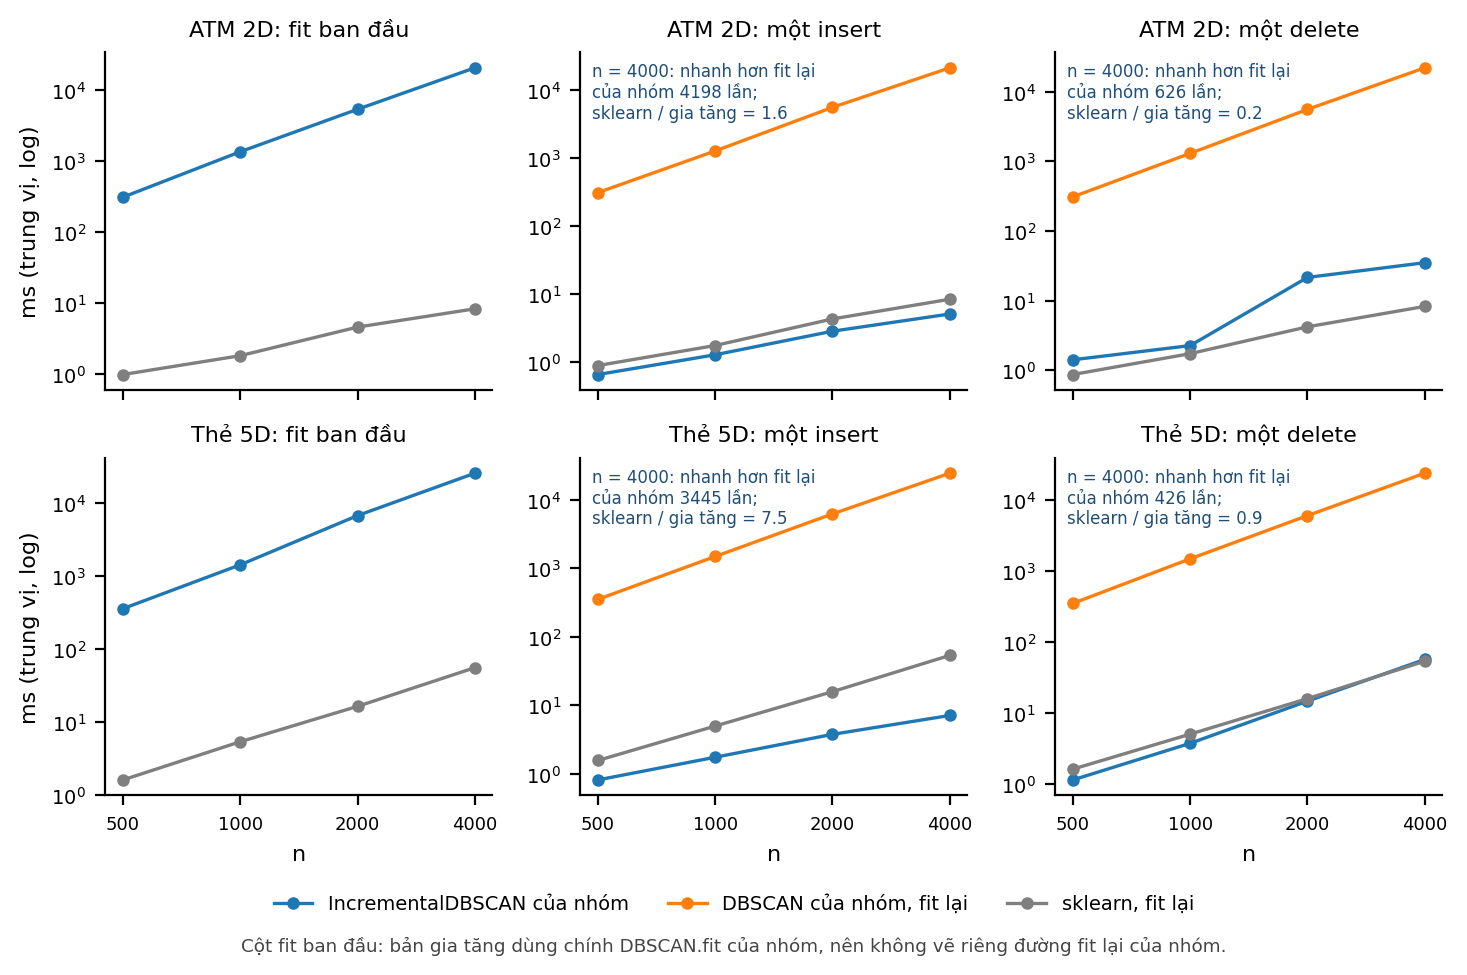

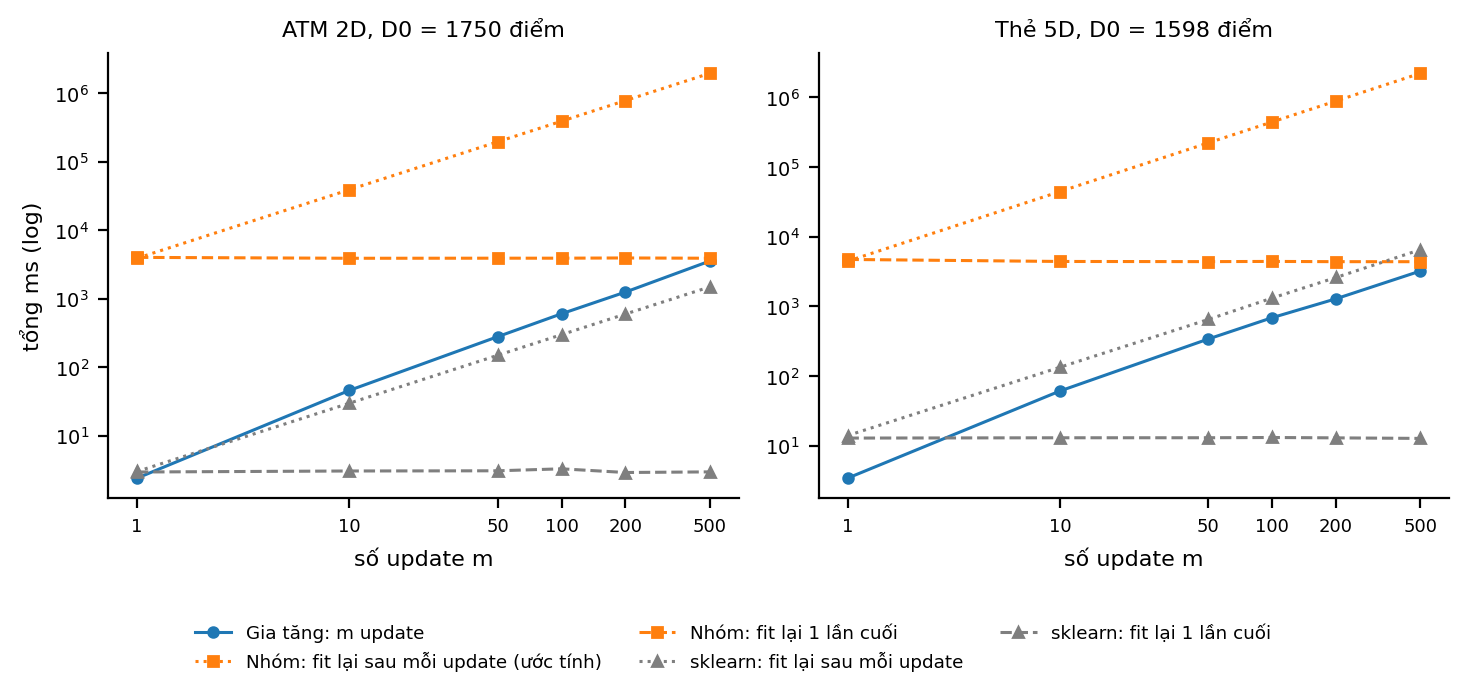

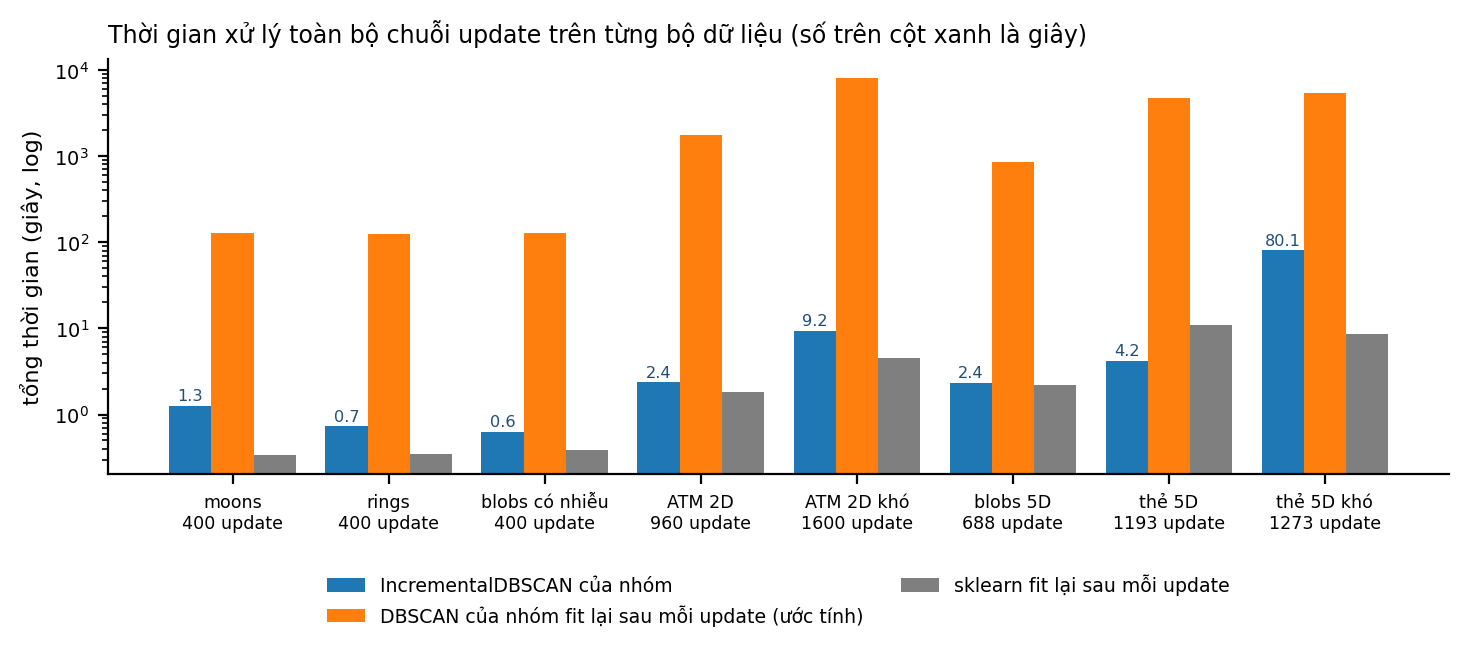

In [41]:
## Hình D09 và mục 2.2 nếu có: thời gian theo n, tổng thời gian theo số update m, thời gian trên tám bộ dữ liệu
for ten_hinh in ('d09_runtime_by_n.png', 'd09_cumulative_by_m.png', 'd22_datasets_time.png'):
    if (Path('report/figures') / ten_hinh).exists():
        display(Image(filename=str(Path('report/figures') / ten_hinh), width=700))

##### *8.2. So sánh các thuật toán dựa trên mật độ trên cùng bản đồ ATM 2D*

Bốn kết quả dưới dùng cùng các điểm và khoảng cách Euclidean. DBSCAN OOP và sklearn DBSCAN dùng `Eps=0.5`, `MinPts=4`. HDBSCAN dùng `min_cluster_size=4`, `min_samples=4`, `eom`. OPTICS dùng `min_samples=4`, `eps=0.5`, `max_eps=0.500001` và trích cụm kiểu DBSCAN.

DBSCAN xác định cụm từ vùng lân cận đủ mật độ; HDBSCAN chọn cụm ổn định từ cấu trúc phân cấp mật độ; OPTICS sắp thứ tự điểm theo khả năng tiếp cận rồi trích cụm. OPTICS dùng cách trích kiểu DBSCAN tại cùng `eps`; HDBSCAN giữ cách trích phân cấp với các tham số riêng.


In [ ]:
## Bảng kết quả: số cụm, noise và độ khớp nhãn
from sklearn.cluster import DBSCAN as SklearnDBSCAN, HDBSCAN, OPTICS

min_pts_demo = int(par_atm['minpts'])
nhan_sklearn_dbscan = SklearnDBSCAN(
    eps=eps_atm, min_samples=min_pts_demo, metric='euclidean', n_jobs=1
).fit_predict(xy_sx)
nhan_hdbscan = HDBSCAN(
    min_cluster_size=min_pts_demo,
    min_samples=min_pts_demo,
    metric='euclidean',
    cluster_selection_method='eom',
    n_jobs=1,
).fit_predict(xy_sx)
nhan_optics = OPTICS(
    min_samples=min_pts_demo,
    max_eps=eps_atm + 1e-6,
    metric='euclidean',
    cluster_method='dbscan',
    eps=eps_atm,
    n_jobs=1,
).fit_predict(xy_sx)

nhan_cac_thuat_toan = {
    'Incremental DBSCAN OOP': nhan_gt,
    'sklearn DBSCAN': nhan_sklearn_dbscan,
    'sklearn HDBSCAN': nhan_hdbscan,
    'sklearn OPTICS': nhan_optics,
}
tham_so_cac_thuat_toan = {
    'Incremental DBSCAN OOP': f'eps={eps_atm}, min_pts={min_pts_demo}; cập nhật cục bộ',
    'sklearn DBSCAN': f'eps={eps_atm}, min_samples={min_pts_demo}; fit lại',
    'sklearn HDBSCAN': f'min_cluster_size={min_pts_demo}, min_samples={min_pts_demo}, eom; fit lại',
    'sklearn OPTICS': f'min_samples={min_pts_demo}, eps={eps_atm}, max_eps={eps_atm + 1e-6}, trích DBSCAN; fit lại',
}
nhan_that = atm_sx['hotspot_id'].to_numpy()
dong_ket_qua = []
for ten, labels in nhan_cac_thuat_toan.items():
    dong_ket_qua.append({
        'Thuật toán': ten,
        'Tham số': tham_so_cac_thuat_toan[ten],
        'Số cụm': len(set(labels.tolist()) - {-1}),
        'Số điểm noise': int((labels == -1).sum()),
        'ARI so với nhãn mô phỏng': adjusted_rand_score(nhan_that, labels),
        'ARI so với Incremental DBSCAN': adjusted_rand_score(nhan_gt, labels),
    })
bang_so_sanh_mat_do = pd.DataFrame(dong_ket_qua).set_index('Thuật toán')
bang_so_sanh_mat_do.round(4)


In [ ]:
## Bản đồ 2D: nhãn mô phỏng và bốn thuật toán cùng nhóm
scores_mat_do = {
    ten: adjusted_rand_score(nhan_that, labels)
    for ten, labels in nhan_cac_thuat_toan.items()
}
fig = plot_algorithm_contrast(
    xy_sx,
    nhan_that,
    nhan_cac_thuat_toan,
    scores={'Nhãn mô phỏng': 1.0, **scores_mat_do},
)


---
#### **9. KẾT LUẬN**

- Nhóm tự cài DBSCAN và Incremental DBSCAN theo OOP; thuật toán trong `src/clustering/` không gọi sklearn để phân cụm. NumPy/Pandas hỗ trợ biểu diễn và xử lý dữ liệu.
- Hai ví dụ ở mục 5 minh họa luồng insert làm gộp cụm và delete làm tách cụm. Vector điểm hỗ trợ nhiều chiều; bản đồ ở mục 8.2 dùng dữ liệu 2D để dễ quan sát.
- Mục 8.2 đối chiếu Incremental DBSCAN OOP, sklearn DBSCAN, HDBSCAN và OPTICS trên cùng bản đồ. OPTICS trích cụm kiểu DBSCAN tại cùng `Eps`/`MinPts` để so sánh nhãn trực tiếp hơn; HDBSCAN giữ tham số và cách trích phân cấp riêng.
- Kết quả thời gian phụ thuộc số điểm, số chiều, cấu hình và vùng bị ảnh hưởng. sklearn trong mục so sánh chạy lại toàn bộ dữ liệu sau mỗi update; không kết luận Incremental DBSCAN luôn nhanh hơn.
- Dữ liệu là mô phỏng. Các kết quả minh họa phạm vi thử nghiệm của nhóm, không đại diện cho mọi bộ dữ liệu.
